# MFE-FCGAT under leave-one-subject-out (LOSO): AD vs HC on ds004504

This is `GAT_ds004504.ipynb` evaluated with **leave-one-subject-out** instead of 5 × 5-fold cross-validation, as
pre-registered in `docs/PREREG_2026-11-17.md` (Part 3). It is a check of where the model stands against
the LOSO papers (Wang et al. 2026: AUC 0.912, accuracy 87.7 %; public benchmark: 0.883, 84.6 %). The 5 × 5
results in `results_gat/` stay the reported ones.

**What changes**
- **Cell 4, splits.** 65 folds: each subject is the test set once. Validation subjects come from the other 64 by
  the 5 × 5 rule (the first fold of a stratified 5-fold split of those subjects, about 13), so about 51 train.
- **Cell 5, the band-power bar.** Balanced class weights: leaving one subject out tilts the training classes
  against that subject's label in every fold. It must reproduce `LOSO_ds004504.ipynb`'s model.
- **Bookkeeping only.** Cell 1 writes to `results_loso/gat/`; Cell 2 sets `N_FOLDS = 65` and `N_REPEATS = 1`
  (LOSO has one partition, and one training seed is pre-registered).

**Unchanged:** the model, LR 3e-3, the cosine schedule over 80 epochs, warm-up 15, patience 20, the epoch chosen
on validation-subject AUC, batch 64, weight decay 1e-4, seed 42, the soft vote and the statistics cell. Cell 11
leaves the 5 × 5 folders out automatically (their `N_FOLDS` differs), so its tests are within LOSO only: network
vs band power, soft vote vs band power, soft vote vs network, Holm over the three.

Needs `subject_cache/` and `results_loso/bandpower_oof.npz` (from `LOSO_ds004504.ipynb`). About 1.5–2 h on CPU.

In [1]:
# ===========================================================================
# CELL 1 — IMPORTS, PATHS, DEVICE
# ===========================================================================
import copy, json, math, random, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

WORK_DIR   = Path.cwd()
CACHE_DIR  = WORK_DIR / "subject_cache"      # point elsewhere if the cache lives elsewhere
RESULT_DIR = WORK_DIR / "results_loso" / "gat"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


print(f"torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"cache   : {CACHE_DIR}  ({len(list(CACHE_DIR.glob('sub-*.npz')))} files)")
print(f"results : {RESULT_DIR}")

torch 2.14.0+cpu | device cpu
cache   : C:\Projects\Major Project\subject_cache  (88 files)
results : C:\Projects\Major Project\results_loso\gat


In [2]:
# ===========================================================================
# CELL 2 — CONFIGURATION  (the only cell you normally edit)
# ===========================================================================
SEED = 42

# --- data: fixed by the cache ----------------------------------------------
BAND_NAMES = ["Delta", "Theta", "Alpha", "Beta", "Gamma"]
BAND_DIMS  = {"Delta": 18, "Theta": 21, "Alpha": 26, "Beta": 86, "Gamma": 76}  # PSD bins @ 0.2 Hz
N_NODES    = 19            # electrodes
N_SUBJECTS = 65            # sub-001..036 AD (label 1), sub-037..065 HC (label 0)
N_AD       = 36

# --- model -------------------------------------------------------------------
CNN_OUT_DIM  = 16          # paper D_out = 16  ->  kernels 3, 6, 11, 71, 61
GAT_HIDDEN   = 16          # layer 1 width (paper's first graph layer)
GAT_OUT      = 5           # layer 2 width (paper's second graph layer)
HEADS        = 4           # attention heads per layer, averaged
ATTN_DROPOUT = 0.1         # dropout on the attention coefficients
MLP_HIDDEN   = (30, 14)    # paper
MLP_DROPOUT  = (0.8, 0.5)  # paper

# --- training (identical to GCN_ds004504.ipynb except LR) --------------------
# Not tuned yet for this model: check 1.2e-4, 1e-3 and 3e-3.
LR           = 3e-3
WEIGHT_DECAY = 1e-4        # from the released code; the paper does not state one
BATCH_SIZE   = 64          # paper
MAX_EPOCHS   = 80          # also the cosine horizon: the LR anneals to ~0 by here
MIN_EPOCHS   = 15          # no checkpoint before this; the earliest epochs are noise
PATIENCE     = 20          # stop after this many epochs without improvement (paper: 20)
GRAD_CLIP    = 5.0

# --- protocol (keep identical across GCN_ds004504 and GAT_ds004504) --------
# "subject": no window from a test subject is ever used in training (honest).
# "window" : windows are shuffled freely. This reproduces the paper's ~95 %,
#            which depends on overlapping windows from the same person landing
#            on both sides of the split. Raise MAX_EPOCHS to ~300 for it.
SPLIT_LEVEL = "subject"
N_FOLDS     = N_SUBJECTS  # leave one subject out: one fold per subject
N_REPEATS   = 1            # LOSO has one partition; one training seed (docs/PREREG_2026-11-17.md)

assert SPLIT_LEVEL in ("subject", "window")
assert [BAND_DIMS[b] - CNN_OUT_DIM + 1 for b in BAND_NAMES] == [3, 6, 11, 71, 61]
seed_all(SEED)
print(f"MFE-FCGAT | lr {LR} | {N_REPEATS} x {N_FOLDS}-fold, {SPLIT_LEVEL}-level | "
      f"max {MAX_EPOCHS} epochs, warm-up {MIN_EPOCHS}, patience {PATIENCE}")

MFE-FCGAT | lr 0.003 | 1 x 65-fold, subject-level | max 80 epochs, warm-up 15, patience 20


In [3]:
# ===========================================================================
# CELL 3 — LOAD THE FEATURE CACHE
# ===========================================================================
# One .npz per subject; one row per 20 s window (75 % overlap):
#   x_<Band>  (n, 19, F_f)       log PSD, normalised per window     paper Eq. 1
#   e1        (n, 5, 19, 19)     |Pearson| graph, row-normalised    Eqs. 2-3
#   e2        (n, 5, 19, 19)     mutual-information graph           Eqs. 4-5
#   bp        (n, 5, 19)         mean log band power (Cells 5 and 10)
x_parts = {b: [] for b in BAND_NAMES}
e1_parts, e2_parts, bp_parts, y_parts, sid_parts = [], [], [], [], []

for i in range(1, N_SUBJECTS + 1):
    sid = f"sub-{i:03d}"
    with np.load(CACHE_DIR / f"{sid}.npz") as z:
        for b in BAND_NAMES:
            assert z[f"x_{b}"].shape[1:] == (N_NODES, BAND_DIMS[b]), (sid, b)
            x_parts[b].append(z[f"x_{b}"])
        e1_parts.append(z["e1"]); e2_parts.append(z["e2"])
        bp_parts.append(z["bp"]); y_parts.append(z["y"])
        sid_parts.append(np.full(len(z["y"]), sid))
    # a re-cached subject must never silently flip class
    assert int(y_parts[-1][0]) == (1 if i <= N_AD else 0), f"{sid}: wrong label"

X   = [np.concatenate(x_parts[b]).astype(np.float32) for b in BAND_NAMES]
E1  = np.concatenate(e1_parts).astype(np.float32)
E2  = np.concatenate(e2_parts).astype(np.float32)
BP  = np.concatenate(bp_parts).astype(np.float32)
Y   = np.concatenate(y_parts).astype(np.int64)
SID = np.concatenate(sid_parts)
del x_parts, e1_parts, e2_parts, bp_parts, y_parts, sid_parts

# The whole dataset (~180 MB) lives on the device; batches are index slices.
Xt  = [torch.from_numpy(a).to(DEVICE) for a in X]
E1t = torch.from_numpy(E1).to(DEVICE)
E2t = torch.from_numpy(E2).to(DEVICE)
Yt  = torch.from_numpy(Y).to(DEVICE)

print(f"windows  : {len(Y):,}  (AD {int((Y == 1).sum()):,} / HC {int((Y == 0).sum()):,})")
print(f"subjects : {len(np.unique(SID))}  (AD {N_AD} / HC {N_SUBJECTS - N_AD})")
for b, a in zip(BAND_NAMES, X):
    print(f"  x_{b:<6s} {a.shape}")
print(f"  e1       {E1.shape}\n  e2       {E2.shape}")

windows  : 5,758  (AD 2,858 / HC 2,900)
subjects : 65  (AD 36 / HC 29)
  x_Delta  (5758, 19, 18)
  x_Theta  (5758, 19, 21)
  x_Alpha  (5758, 19, 26)
  x_Beta   (5758, 19, 86)
  x_Gamma  (5758, 19, 76)
  e1       (5758, 5, 19, 19)
  e2       (5758, 5, 19, 19)


In [4]:
# ===========================================================================
# CELL 4 — SPLITS AND METRICS
# ===========================================================================
def make_splits(n_repeats=N_REPEATS, seed=SEED):
    """Leave one subject out: each of the 65 subjects is the test set once (docs/PREREG_2026-11-17.md, Part 3).

    Validation subjects come from the other 64 by the 5 x 5 rule: the first fold of a stratified 5-fold split of
    those subjects (about 13), so early stopping is never judged on people the model is training on.
    """
    splits, subjects = [], np.unique(SID)
    for r in range(1, n_repeats + 1):
        rs = seed + 1000 * r
        for f, s in enumerate(subjects, start=1):
            test, trainval = np.flatnonzero(SID == s), np.flatnonzero(SID != s)
            inner = StratifiedKFold(5, shuffle=True, random_state=rs + f)
            subs = np.unique(SID[trainval])
            labs = np.array([Y[SID == u][0] for u in subs])
            _, va = next(inner.split(subs, labs))
            is_val = np.isin(SID[trainval], subs[va])
            train, val = trainval[~is_val], trainval[is_val]
            tr_s, va_s, te_s = set(SID[train]), set(SID[val]), set(SID[test])
            assert not (tr_s & te_s or va_s & te_s or tr_s & va_s), "SUBJECT LEAKAGE"
            splits.append(dict(repeat=r, fold=f, train=train, val=val, test=test))
    return splits


def _metrics(y, p):
    pred = (p >= 0.5).astype(int)
    return dict(acc=accuracy_score(y, pred),
                sens=recall_score(y, pred, zero_division=0),
                spec=recall_score(1 - y, 1 - pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0),
                auc=roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan)


def score(idx, prob):
    """Window-level (w_*) and subject-level (s_*) metrics.
    A subject's probability is the mean over its windows."""
    sid, y = SID[idx], Y[idx]
    subs = np.unique(sid)
    s_p = np.array([prob[sid == s].mean() for s in subs])
    s_y = np.array([y[sid == s][0] for s in subs])
    return {**{f"w_{k}": v for k, v in _metrics(y, prob).items()},
            **{f"s_{k}": v for k, v in _metrics(s_y, s_p).items()}}


SPLITS = make_splits()
_ns = lambda i: len(np.unique(SID[i]))
for s in SPLITS:
    print(f"r{s['repeat']} f{s['fold']}: train {len(s['train']):5d}w/{_ns(s['train']):2d}s | "
          f"val {len(s['val']):4d}w/{_ns(s['val']):2d}s | test {len(s['test']):4d}w/{_ns(s['test']):2d}s")
_tested = np.concatenate([s["test"] for s in SPLITS if s["repeat"] == 1])
assert len(_tested) == len(np.unique(_tested)) == len(Y)
print(f"each repeat tests all {len(Y):,} windows / {_ns(_tested)} subjects exactly once")

r1 f1: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f2: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f3: train  4540w/51s | val 1160w/13s | test   58w/ 1s
r1 f4: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f5: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f6: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f7: train  4540w/51s | val 1138w/13s | test   80w/ 1s
r1 f8: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f9: train  4540w/51s | val 1138w/13s | test   80w/ 1s
r1 f10: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f11: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f12: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f13: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f14: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f15: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f16: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f17: train  4518w/51s | val 1160w/13s | test   80w/ 1s
r1 f18: train  4518w/51

In [5]:
# ===========================================================================
# CELL 5 — THE BAR: band power -> logistic regression, on the network's folds
# ===========================================================================
# Uses 95 numbers per window (5 bands x 19 electrodes), with no graph and no
# learning of structure. It is fitted on the train + validation subjects of
# every fold in SPLITS and tested on the same test subjects as the network,
# scored the same way: a subject's score is the mean of its window probabilities.
# A graph model has to beat this to justify its parameters. The network trains
# on the train subjects only (validation subjects pick its epoch), so the floor
# learns from ~25 % more subjects: the comparison favours the floor, not the network.
# LOSO (docs/PREREG_2026-11-17.md, Part 3): balanced class weights, and the fit rows in sorted order, so this
# reproduces the primary band-power model of LOSO_ds004504.ipynb. The features are float32, so the solution
# moves by ~1e-3 with the number of BLAS threads; fitting in the same worker processes as that notebook
# reproduces it exactly.
import os
from joblib import Parallel, delayed


def _fit_floor(sp):
    fit = np.sort(np.concatenate([sp["train"], sp["val"]]))
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced"))
    return clf.fit(feat[fit], Y[fit]).predict_proba(feat[sp["test"]])[:, 1]


feat = BP.reshape(len(BP), -1)
FLOOR_OOF = np.full((N_REPEATS, len(Y)), np.nan)    # out-of-fold P(AD), one row per repeat
_jobs = max(1, min(8, (os.cpu_count() or 2) - 2))   # LOSO_ds004504.ipynb's worker count
for sp, p in zip(SPLITS, Parallel(n_jobs=_jobs)(delayed(_fit_floor)(sp) for sp in SPLITS)):
    FLOOR_OOF[sp["repeat"] - 1, sp["test"]] = p

_part1 = np.load(WORK_DIR / "results_loso" / "bandpower_oof.npz")
_ref   = _part1[f"window_p_{list(_part1['runs']).index('LOSO, balanced (primary)')}"]
_diff  = np.abs(FLOOR_OOF - _ref).max()
assert _diff < 1e-6, f"the band-power model differs from LOSO_ds004504.ipynb (max |diff| {_diff:.1e})"
print(f"band-power model reproduces LOSO_ds004504.ipynb (max |diff| {_diff:.1e})")

FLOOR = pd.DataFrame([score(np.arange(len(Y)), FLOOR_OOF[r]) for r in range(N_REPEATS)]).mean()
print(f"linear floor, subject level : acc {FLOOR['s_acc']:.4f}  recall {FLOOR['s_sens']:.4f}  "
      f"spec {FLOOR['s_spec']:.4f}  AUC {FLOOR['s_auc']:.4f}   (same folds as the network)")

band-power model reproduces LOSO_ds004504.ipynb (max |diff| 0.0e+00)
linear floor, subject level : acc 0.7692  recall 0.8056  spec 0.7241  AUC 0.8966   (same folds as the network)


---
## Model

Three things to know before reading the code:

- **Why `+ log E`.** Every graph links all 19 electrodes to each other. A plain
  GAT would have no structure to work from, so the Pearson and MI graphs would
  be ignored. Adding `log E` inside the softmax is the same as multiplying the
  attention by `E` and renormalising. At the start of training the layer is a
  connectivity-weighted average, close to the GCN. Training then reshapes the
  weights.
- **Why classic GAT is enough.** In classic GAT the learned score
  `a·Wx_i + a·Wx_j` ranks neighbours the same way for every electrode. This is
  the weakness GATv2 was designed to fix. The `log E` term is different for
  each pair and each window, so the final attention still varies by electrode.
  In earlier runs in this project (`results_mfagat/C_attn_v1`), the classic
  layer was also the faster and higher-scoring GAT variant.
- **Pearson first, MI second**, as in paper Eq. 8, with separate weights for
  each band. The only difference from `GCN_ds004504.ipynb` is `BandGAT` here
  versus `BandGCN` there.

In [6]:
# ===========================================================================
# CELL 6 — MODEL
# ===========================================================================
class BandCNN(nn.Module):
    """Paper Eq. 6: one Conv1d(1, 1, D_f) per band, shared across the 19 electrodes.

    D_f = F_f - 16 + 1, so every band comes out 16 wide and keeps its frequency order.
    """
    def __init__(self):
        super().__init__()
        self.convs = nn.ModuleList([nn.Conv1d(1, 1, BAND_DIMS[b] - CNN_OUT_DIM + 1)
                                    for b in BAND_NAMES])

    def forward(self, x, band):                    # (B, 19, F_f) -> (B, 19, 16)
        b, n, f = x.shape
        return self.convs[band](x.reshape(b * n, 1, f)).reshape(b, n, CNN_OUT_DIM)


class GATLayer(nn.Module):
    """Classic multi-head GAT (Velickovic et al. 2018), dense over 19 electrodes.

        h_i   = W x_i                                    (per head)
        e_ij  = LeakyReLU(a_src . h_i + a_dst . h_j) + log E_ij
        alpha = softmax_j(e_ij)
        out_i = mean over heads of  sum_j alpha_ij h_j
    """
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.heads, self.out_dim = HEADS, out_dim
        self.W     = nn.Linear(in_dim, HEADS * out_dim, bias=False)
        self.a_src = nn.Parameter(torch.empty(HEADS, 1, out_dim))
        self.a_dst = nn.Parameter(torch.empty(HEADS, 1, out_dim))
        self.bias  = nn.Parameter(torch.zeros(out_dim))
        self.drop  = nn.Dropout(ATTN_DROPOUT)
        for w in (self.W.weight, self.a_src, self.a_dst):
            nn.init.xavier_uniform_(w, gain=math.sqrt(2.0))

    def forward(self, x, adj):                     # x (B, 19, in), adj (B, 19, 19)
        b, n, _ = x.shape
        h   = self.W(x).view(b, n, self.heads, self.out_dim).transpose(1, 2)  # (B, H, 19, d)
        src = (h * self.a_src).sum(-1)                                        # (B, H, 19)
        dst = (h * self.a_dst).sum(-1)
        e   = F.leaky_relu(src.unsqueeze(-1) + dst.unsqueeze(-2), 0.2)        # (B, H, 19, 19)
        e   = e + torch.log(adj.clamp(min=1e-8)).unsqueeze(1)   # clamp: log(0) = -inf breaks softmax
        alpha = self.drop(torch.softmax(e, dim=-1))
        return (alpha @ h).mean(1) + self.bias                                # (B, 19, d)


class BandGAT(nn.Module):
    """Eq. 8 with attention in place of convolution: Pearson graph, then MI graph."""
    def __init__(self):
        super().__init__()
        self.g1 = GATLayer(CNN_OUT_DIM, GAT_HIDDEN)
        self.g2 = GATLayer(GAT_HIDDEN, GAT_OUT)

    def forward(self, x, e1, e2):                  # (B, 19, 16) -> (B, 19, 5)
        return F.elu(self.g2(F.elu(self.g1(x, e1)), e2))


class MFEFCGAT(nn.Module):
    """BandCNN -> per-band BandGAT -> concat 5 x 19 x 5 = 475 (Eq. 9) -> MLP."""
    def __init__(self):
        super().__init__()
        self.cnn  = BandCNN()
        self.gats = nn.ModuleList([BandGAT() for _ in BAND_NAMES])
        self.head = nn.Sequential(
            nn.Linear(len(BAND_NAMES) * N_NODES * GAT_OUT, MLP_HIDDEN[0]), nn.ReLU(),
            nn.Dropout(MLP_DROPOUT[0]),
            nn.Linear(MLP_HIDDEN[0], MLP_HIDDEN[1]), nn.ReLU(),
            nn.Dropout(MLP_DROPOUT[1]),
            nn.Linear(MLP_HIDDEN[1], 2))

    def forward(self, xs, e1, e2):                 # xs: 5 x (B, 19, F_f); e1, e2: (B, 5, 19, 19)
        z = [self.gats[i](self.cnn(xs[i], i), e1[:, i], e2[:, i]).flatten(1)
             for i in range(len(BAND_NAMES))]
        return self.head(torch.cat(z, dim=1))      # logits (B, 2)


_m  = MFEFCGAT()
_xs = [torch.randn(8, N_NODES, BAND_DIMS[b]) for b in BAND_NAMES]
_e  = torch.rand(8, len(BAND_NAMES), N_NODES, N_NODES)
print(f"parameters : {sum(p.numel() for p in _m.parameters()):,}   (GCN version: 16,686)")
print(f"smoke test : logits {tuple(_m(_xs, _e, _e).shape)}")
del _m, _xs, _e

parameters : 22,566   (GCN version: 16,686)


smoke test : logits (8, 2)

In [7]:
# ===========================================================================
# CELL 7 — TRAINING
# ===========================================================================
def batches(idx, size=BATCH_SIZE, shuffle=False, rng=None):
    order = rng.permutation(len(idx)) if shuffle else np.arange(len(idx))
    for s in range(0, len(idx), size):
        sel = torch.as_tensor(idx[order[s:s + size]], device=DEVICE)
        yield [x[sel] for x in Xt], E1t[sel], E2t[sel], Yt[sel]


@torch.no_grad()
def predict(model, idx):
    """P(AD) for each window, in the order of idx."""
    model.eval()
    return torch.cat([torch.softmax(model(xs, e1, e2), 1)[:, 1]
                      for xs, e1, e2, _ in batches(idx, size=512)]).cpu().numpy()


def train_fold(split):
    """Train on split['train'], keep the epoch with the best validation AUC, predict test."""
    seed = SEED + 1000 * split["repeat"] + split["fold"]
    seed_all(seed)
    rng = np.random.default_rng(seed)

    model = MFEFCGAT().to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS, eta_min=LR * 0.01)
    key   = "s_auc" if SPLIT_LEVEL == "subject" else "w_auc"   # select on what gets reported

    best, best_epoch, best_state, stale, history = -np.inf, 0, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        lr, total = opt.param_groups[0]["lr"], 0.0
        for xs, e1, e2, y in batches(split["train"], shuffle=True, rng=rng):
            loss = F.cross_entropy(model(xs, e1, e2), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            total += loss.item() * len(y)
        sched.step()

        val = score(split["val"], predict(model, split["val"]))
        history.append(dict(epoch=epoch, lr=lr, train_loss=total / len(split["train"]),
                            val_w_auc=val["w_auc"], val_s_acc=val["s_acc"], val_s_auc=val["s_auc"]))

        if epoch < MIN_EPOCHS:
            continue
        if val[key] > best:
            best, best_epoch, stale = val[key], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
            if stale >= PATIENCE:
                break

    model.load_state_dict(best_state)
    return dict(best_epoch=best_epoch, epochs_run=epoch,
                test_prob=predict(model, split["test"]), history=pd.DataFrame(history))


print("training functions ready")

training functions ready


In [8]:
# ===========================================================================
# CELL 8 — CROSS-VALIDATION
# ===========================================================================
rows, HISTORY = [], {}
OOF = np.full((N_REPEATS, len(Y)), np.nan)        # out-of-fold P(AD), one row per repeat
t0 = time.time()

for sp in SPLITS:
    ts = time.time()
    r = train_fold(sp)
    OOF[sp["repeat"] - 1, sp["test"]] = r["test_prob"]
    m = score(sp["test"], r["test_prob"])
    rows.append(dict(repeat=sp["repeat"], fold=sp["fold"], best_epoch=r["best_epoch"],
                     epochs_run=r["epochs_run"], seconds=round(time.time() - ts), **m))
    HISTORY[(sp["repeat"], sp["fold"])] = r["history"]
    r["history"].to_csv(RESULT_DIR / f"history_r{sp['repeat']}_f{sp['fold']}.csv", index=False)
    print(f"r{sp['repeat']} f{sp['fold']}  best epoch {r['best_epoch']:2d}/{r['epochs_run']:2d}  "
          f"window acc {m['w_acc']:.4f} auc {m['w_auc']:.4f}  |  "
          f"subject acc {m['s_acc']:.4f} auc {m['s_auc']:.4f}  [{rows[-1]['seconds']}s]", flush=True)

FOLDS = pd.DataFrame(rows)
FOLDS.to_csv(RESULT_DIR / "fold_results.csv", index=False)
np.save(RESULT_DIR / "oof_prob.npy", OOF)

# Pooled out-of-fold score: each repeat scores all 65 subjects once, each by a
# model that never saw them. This is the number to quote.
POOLED = pd.DataFrame([score(np.arange(len(Y)), OOF[r]) for r in range(N_REPEATS)])
P    = POOLED.mean()
P_SD = POOLED.std(ddof=1) if N_REPEATS > 1 else P * 0
pm = lambda k: f"{P[k]:.4f}" + (f" +- {P_SD[k]:.4f}" if N_REPEATS > 1 else "")

print(f"\nPOOLED  window  acc {pm('w_acc')}  auc {pm('w_auc')}")
print(f"POOLED  subject acc {pm('s_acc')}  auc {pm('s_auc')}  "
      f"sens {P['s_sens']:.4f}  spec {P['s_spec']:.4f}   [{(time.time() - t0) / 60:.1f} min]")

(RESULT_DIR / "summary.json").write_text(json.dumps(dict(
    model="MFE-FCGAT", pooled=P.to_dict(), pooled_sd=P_SD.to_dict(), floor=FLOOR.to_dict(),
    config=dict(LR=LR, WEIGHT_DECAY=WEIGHT_DECAY, BATCH_SIZE=BATCH_SIZE, MAX_EPOCHS=MAX_EPOCHS,
                MIN_EPOCHS=MIN_EPOCHS, PATIENCE=PATIENCE, GRAD_CLIP=GRAD_CLIP,
                CNN_OUT_DIM=CNN_OUT_DIM, GAT_HIDDEN=GAT_HIDDEN, GAT_OUT=GAT_OUT, HEADS=HEADS, ATTN_DROPOUT=ATTN_DROPOUT,
                MLP_HIDDEN=MLP_HIDDEN, MLP_DROPOUT=MLP_DROPOUT,
                SPLIT_LEVEL=SPLIT_LEVEL, N_FOLDS=N_FOLDS, N_REPEATS=N_REPEATS, SEED=SEED)), indent=2))

r1 f1  best epoch 18/38  window acc 1.0000 auc nan  |  subject acc 1.0000 auc nan  [241s]


r1 f2  best epoch 33/53  window acc 0.8125 auc nan  |  subject acc 1.0000 auc nan  [314s]


r1 f3  best epoch 33/53  window acc 0.6034 auc nan  |  subject acc 1.0000 auc nan  [334s]


r1 f4  best epoch 15/35  window acc 1.0000 auc nan  |  subject acc 1.0000 auc nan  [216s]


r1 f5  best epoch 17/37  window acc 0.6375 auc nan  |  subject acc 1.0000 auc nan  [227s]


r1 f6  best epoch 26/46  window acc 0.4000 auc nan  |  subject acc 0.0000 auc nan  [285s]


... (57 outputs left out)

r1 f64  best epoch 15/35  window acc 1.0000 auc nan  |  subject acc 1.0000 auc nan  [89s]


r1 f65  best epoch 16/36  window acc 0.8000 auc nan  |  subject acc 1.0000 auc nan  [93s]



POOLED  window  acc 0.7727  auc 0.8428
POOLED  subject acc 0.8462  auc 0.9148  sens 0.8333  spec 0.8621   [146.8 min]


1380

note: results_gcn/ used a different protocol, so it is left out

subject level, pooled over 65               acc      AUC     sens     spec
--------------------------------------------------------------------------
MFE-FCGAT (this run, lr 0.003)           0.8462   0.9148   0.8333   0.8621
band-power LR, same folds                0.7692   0.8966   0.8056   0.7241
run GCN_ds004504.ipynb to add MFE-FCGCN to this table
vs linear floor: acc +0.0769   AUC +0.0182   (Cell 11 tests whether this is real)

best epochs: [18, 33, 33, 15, 17, 26, 35, 15, 31, 16, 16, 15, 15, 15, 15, 24, 15, 15, 15, 16, 15, 15, 30, 15, 15, 32, 17, 25, 32, 26, 17, 18, 15, 15, 15, 28, 15, 25, 34, 15, 15, 19, 30, 15, 15, 15, 16, 15, 38, 15, 16, 22, 15, 17, 15, 16, 17, 19, 15, 21, 37, 15, 15, 15, 16]   (warm-up 15, cap 80)

55/65 subjects correct; misclassified:
subject label  p_ad called  correct
sub-036    AD 0.086     HC    False
sub-010    AD 0.259     HC    False
sub-030    AD 0.263     HC    False
sub-025    AD 0.2

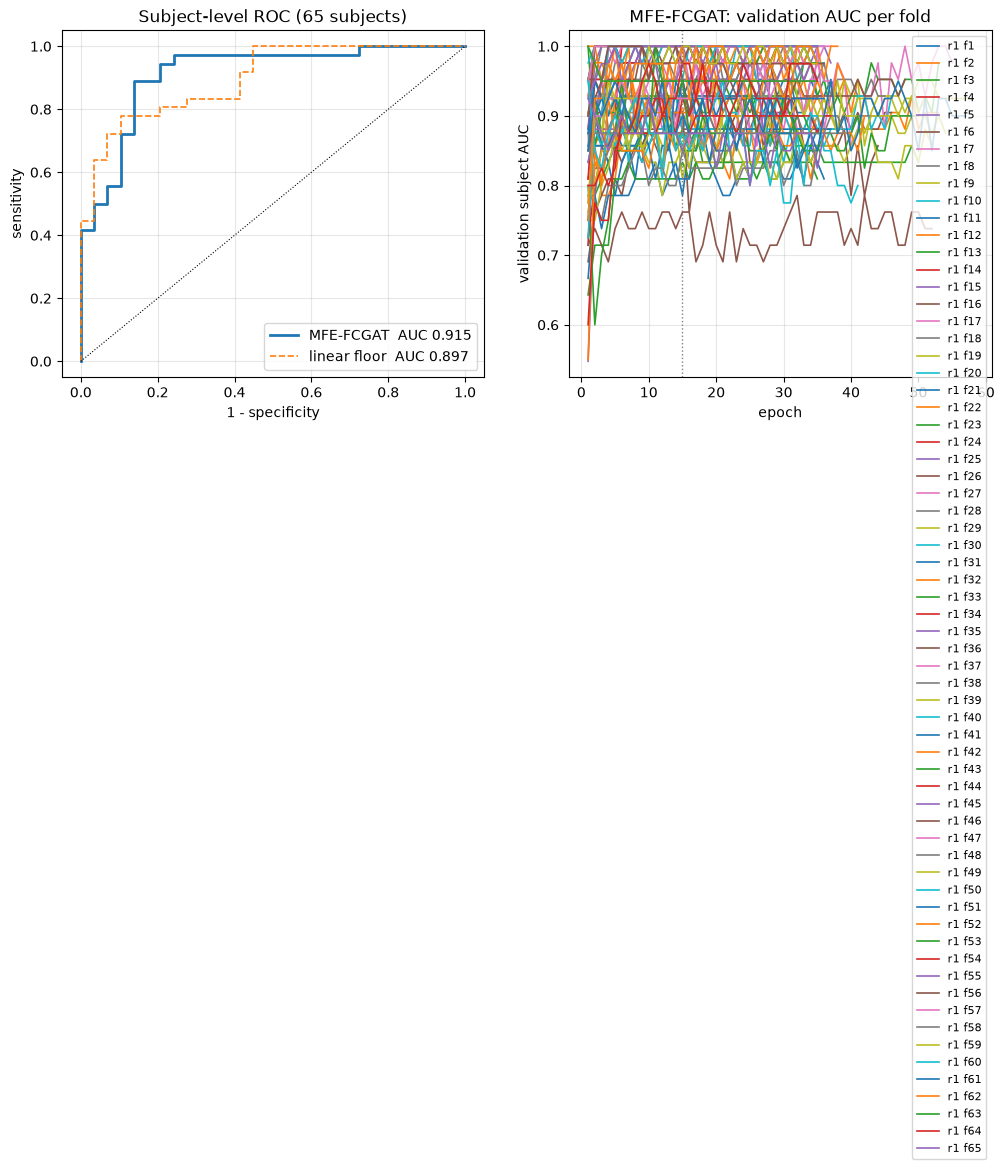

In [9]:
# ===========================================================================
# CELL 9 — RESULTS
# ===========================================================================
# The other architecture is shown too if its notebook has been run next to this
# one with the same protocol (same splits, so the comparison is like-for-like).
OTHER_DIR = WORK_DIR / "results_gcn"
other = (json.loads((OTHER_DIR / "summary.json").read_text())
         if (OTHER_DIR / "summary.json").exists() else None)
if other and any(other["config"][k] != v for k, v in
                 dict(SEED=SEED, N_FOLDS=N_FOLDS, N_REPEATS=N_REPEATS, SPLIT_LEVEL=SPLIT_LEVEL).items()):
    print(f"note: {OTHER_DIR.name}/ used a different protocol, so it is left out\n")
    other = None

table = [(f"MFE-FCGAT (this run, lr {LR:g})", P)]
if other:
    table.append((f"MFE-FCGCN ({OTHER_DIR.name}, lr {other['config']['LR']:g})", pd.Series(other["pooled"])))

print("=" * 74)
print(f"{'subject level, pooled over 65':38s}{'acc':>9s}{'AUC':>9s}{'sens':>9s}{'spec':>9s}")
print("-" * 74)
for name, p in table:
    print(f"{name:38s}{p['s_acc']:9.4f}{p['s_auc']:9.4f}{p['s_sens']:9.4f}{p['s_spec']:9.4f}")
print(f"{'band-power LR, same folds':38s}{FLOOR['s_acc']:9.4f}{FLOOR['s_auc']:9.4f}"
      f"{FLOOR['s_sens']:9.4f}{FLOOR['s_spec']:9.4f}")
print("=" * 74)
if not other:
    print("run GCN_ds004504.ipynb to add MFE-FCGCN to this table")
print(f"vs linear floor: acc {P['s_acc'] - FLOOR['s_acc']:+.4f}   AUC {P['s_auc'] - FLOOR['s_auc']:+.4f}"
      "   (Cell 11 tests whether this is real)")

# --- was the learning rate sensible? -----------------------------------------
print(f"\nbest epochs: {FOLDS.best_epoch.tolist()}   (warm-up {MIN_EPOCHS}, cap {MAX_EPOCHS})")
if (FOLDS.best_epoch == MIN_EPOCHS).mean() >= 0.6:
    print("  -> most folds peaked at the warm-up floor: the model overshoots early; try a lower LR")
elif (FOLDS.epochs_run == MAX_EPOCHS).mean() >= 0.6:
    print("  -> most folds were still improving at the cap: try a higher LR or more epochs")

# --- which subjects are wrong? ------------------------------------------------
_p = np.nanmean(OOF, axis=0)
PER_SUBJECT = pd.DataFrame([dict(subject=s, label="AD" if Y[SID == s][0] else "HC",
                                 p_ad=_p[SID == s].mean()) for s in np.unique(SID)])
PER_SUBJECT["called"]  = np.where(PER_SUBJECT.p_ad > 0.5, "AD", "HC")
PER_SUBJECT["correct"] = PER_SUBJECT.called == PER_SUBJECT.label
PER_SUBJECT.to_csv(RESULT_DIR / "per_subject.csv", index=False)
print(f"\n{PER_SUBJECT.correct.sum()}/{len(PER_SUBJECT)} subjects correct; misclassified:")
print(PER_SUBJECT[~PER_SUBJECT.correct].sort_values("p_ad").to_string(
    index=False, float_format=lambda v: f"{v:.3f}"))

# --- plots --------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
_y = (PER_SUBJECT.label == "AD").astype(int)
ax[0].plot(*roc_curve(_y, PER_SUBJECT.p_ad)[:2], lw=2,
           label=f"MFE-FCGAT  AUC {roc_auc_score(_y, PER_SUBJECT.p_ad):.3f}")
if other:
    _o  = np.nanmean(np.load(OTHER_DIR / "oof_prob.npy"), axis=0)
    _op = np.array([_o[SID == s].mean() for s in PER_SUBJECT.subject])
    ax[0].plot(*roc_curve(_y, _op)[:2], lw=1.5, label=f"MFE-FCGCN  AUC {roc_auc_score(_y, _op):.3f}")
_f  = np.nanmean(FLOOR_OOF, axis=0)
_fp = np.array([_f[SID == s].mean() for s in PER_SUBJECT.subject])
ax[0].plot(*roc_curve(_y, _fp)[:2], lw=1.2, ls="--", label=f"linear floor  AUC {roc_auc_score(_y, _fp):.3f}")
ax[0].plot([0, 1], [0, 1], "k:", lw=0.8)
ax[0].set(xlabel="1 - specificity", ylabel="sensitivity", title="Subject-level ROC (65 subjects)")
ax[0].legend(); ax[0].grid(alpha=0.3)

for (r, f), h in HISTORY.items():
    ax[1].plot(h.epoch, h.val_s_auc, lw=1.2, label=f"r{r} f{f}")
ax[1].axvline(MIN_EPOCHS, color="grey", ls=":", lw=1)
ax[1].set(xlabel="epoch", ylabel="validation subject AUC", title="MFE-FCGAT: validation AUC per fold")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RESULT_DIR / "summary.png", dpi=140)
plt.show()

---
## Ensemble: network + band power (soft vote)

The graph network and the band-power logistic regression make different
mistakes, so averaging their probabilities helps. The weights are equal and
fixed in advance, so nothing is tuned on test subjects. Both models are scored
on the same test subjects. The cell reads the network's saved out-of-fold
probabilities, so after a restart it only needs Cells 1–5, not another training
run.

In [10]:
# ===========================================================================
# CELL 10 — ENSEMBLE: network + band-power floor (soft vote, no extra training)
# ===========================================================================
# FLOOR_OOF comes from Cell 5 (the network's own folds), so all three rows
# below are scored on identical test subjects.

NET_OOF = np.load(RESULT_DIR / "oof_prob.npy")
assert NET_OOF.shape == FLOOR_OOF.shape, "run Cell 8 with the same N_REPEATS first"
ENS_OOF = (NET_OOF + FLOOR_OOF) / 2
np.save(RESULT_DIR / "ensemble_oof_prob.npy", ENS_OOF)

ENS = {}
print("=" * 86)
print(f"{'pooled over 65 subjects':38s}{'acc':>8s}{'recall':>8s}{'spec':>8s}{'AUC':>8s}{'win acc':>8s}{'win AUC':>8s}")
print("-" * 86)
for name, oof in [(f"this network (lr {LR:g})", NET_OOF), ("band-power LR, same folds", FLOOR_OOF),
                  ("soft vote: network + band power", ENS_OOF)]:
    m = pd.DataFrame([score(np.arange(len(Y)), oof[r]) for r in range(N_REPEATS)]).mean()
    ENS[name] = m
    print(f"{name:38s}" + "".join(f"{m[c]:8.4f}" for c in ["s_acc", "s_sens", "s_spec", "s_auc", "w_acc", "w_auc"]))
print("=" * 86)
_ = (RESULT_DIR / "ensemble_summary.json").write_text(json.dumps({k: v.to_dict() for k, v in ENS.items()}, indent=2))

pooled over 65 subjects                    acc  recall    spec     AUC win acc win AUC
--------------------------------------------------------------------------------------
this network (lr 0.003)                 0.8462  0.8333  0.8621  0.9148  0.7727  0.8428
band-power LR, same folds               0.7692  0.8056  0.7241  0.8966  0.7636  0.8528
soft vote: network + band power         0.8154  0.8056  0.8276  0.9253  0.7841  0.8737


---
## Statistics: is a difference real?

One AUC measured on 65 subjects has a 95 % confidence interval of about ±0.06,
wider than most architecture effects in this project. This cell gives every
number a confidence interval and every comparison a paired test, so a gap is
called real only when the data can support it. It reads the saved out-of-fold
probabilities only, so after a restart it needs Cells 1–5 and 10, not another
training run. The other notebooks (`GAT_ds004504`, `GCN_ds004504`, the no-graph
control, the random forest, `GATv2_ds004504`, `GATv2gate_ds004504`) join the tables
automatically when they were run on the same folds and the same number of repeats.

In [11]:
# ===========================================================================
# CELL 11 — STATISTICS: which differences are larger than chance?
# ===========================================================================
# Every comparison is paired: the same 65 subjects, tested on the same folds.
# Each number is the metric of one trained model averaged over the repeats
# (the number the tables above report), and each test is about that number.
#   95 % CI  bootstrap over subjects (AD and HC resampled separately). Each
#            resample recomputes the repeat-averaged metric of both models, so a
#            subject's predictions from all repeats move together.
#   p        two-sided bootstrap p: how often the resampled difference lands on
#            the other side of zero. p < 0.05 exactly when the CI excludes 0.
#   Holm     corrects the AUC p for running several comparisons at once.
#            This is the p to quote.
# Not DeLong: it scores one set of predictions, and averaging probabilities
# over repeats would test a 5-run ensemble instead of the reported number.
# Other result folders join only if they used the same protocol (same SEED,
# N_FOLDS, N_REPEATS and SPLIT_LEVEL, hence the same folds). No training.
N_BOOT       = 2000
COMPARE_DIRS = ["results_gat", "results_gcn", "results_gat_nograph", "results_rf",
                "results_gatv2", "results_gatv2gate"]
PROTOCOL     = dict(SEED=SEED, N_FOLDS=N_FOLDS, N_REPEATS=N_REPEATS, SPLIT_LEVEL=SPLIT_LEVEL)

_subs, _inv = np.unique(SID, return_inverse=True)              # same subject order as score()
S_Y = np.array([Y[_inv == k][0] for k in range(len(_subs))])
_pos, _neg = np.where(S_Y == 1)[0], np.where(S_Y == 0)[0]
_rng  = np.random.default_rng(SEED)
_bpos = _pos[_rng.integers(0, len(_pos), (N_BOOT, len(_pos)))]  # one resample of the AD subjects per row
_bneg = _neg[_rng.integers(0, len(_neg), (N_BOOT, len(_neg)))]  # ... and of the HC subjects


def to_subjects(oof):
    """(repeats, windows) P(AD) -> (repeats, subjects): mean over each subject's windows."""
    return np.stack([np.bincount(_inv, weights=o) / np.bincount(_inv) for o in oof])


def _auc(pos, neg):
    """AUC along the last axis: the chance that a random AD subject outscores a random HC subject."""
    d = pos[..., :, None] - neg[..., None, :]
    return (d > 0).mean((-2, -1)) + 0.5 * (d == 0).mean((-2, -1))


def metrics(sp, pos=_pos, neg=_neg):
    """Subject-level metrics averaged over repeats. sp: (repeats, subjects).
    pos/neg: 1-D for the real sample, or 2-D with one bootstrap resample per row."""
    hit = (sp >= 0.5) == S_Y                                   # the 0.5 cut, as in score()
    sens, spec = hit[:, pos].mean(-1), hit[:, neg].mean(-1)
    n_pos, n_neg = pos.shape[-1], neg.shape[-1]
    return dict(auc=_auc(sp[:, pos], sp[:, neg]).mean(0), sens=sens.mean(0), spec=spec.mean(0),
                acc=((sens * n_pos + spec * n_neg) / (n_pos + n_neg)).mean(0))


def boot_p(d):
    """Two-sided bootstrap p for 'no difference', from the resampled differences d."""
    return min(1.0, 2 * (min((d <= 0).sum(), (d >= 0).sum()) + 1) / (len(d) + 1))


def holm(p):
    """Holm-Bonferroni adjusted p-values, in the input order."""
    p, out, run = np.asarray(p, float), np.empty(len(p)), 0.0
    for k, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - k) * p[i])
        out[i] = min(1.0, run)
    return out


# --- the models: this notebook's three, plus any other run on the same folds --
MODELS = {"network": NET_OOF, "LR floor": FLOOR_OOF, "soft vote": ENS_OOF}
for d in COMPARE_DIRS:
    path = WORK_DIR / d
    if path == RESULT_DIR or not (path / "oof_prob.npy").exists():
        continue
    s, oof = json.loads((path / "summary.json").read_text()), np.load(path / "oof_prob.npy")
    if any(s["config"].get(k) != v for k, v in PROTOCOL.items()) or oof.shape != NET_OOF.shape:
        print(f"note: {d}/ used a different protocol, so it is left out")
        continue
    MODELS[s.get("model", d)] = oof

SUBJ = {k: to_subjects(v) for k, v in MODELS.items()}
REAL = {k: metrics(v) for k, v in SUBJ.items()}
BOOT = {k: metrics(v, _bpos, _bneg) for k, v in SUBJ.items()}
ci = lambda v, f="": f"[{np.percentile(v, 2.5):{f}.3f}, {np.percentile(v, 97.5):{f}.3f}]"

print(f"network = this notebook ({RESULT_DIR.name});  soft vote = network + LR floor (Cell 10)")
print("=" * 104)
print(f"{f'{len(_subs)} subjects, {N_REPEATS} rep.':16s}"
      + "".join(f"{h:>22s}" for h in ["AUC [95% CI]", "recall", "specificity", "accuracy"]))
print("-" * 104)
for k in MODELS:
    print(f"{k:16s}" + "".join(f"{REAL[k][m]:7.3f} {ci(BOOT[k][m])}" for m in ["auc", "sens", "spec", "acc"]))
print("=" * 104)

# --- paired comparisons ---------------------------------------------------------
PAIRS  = [("network", "LR floor"), ("soft vote", "LR floor"), ("soft vote", "network")]
PAIRS += [("network", k) for k in MODELS if k not in ("network", "LR floor", "soft vote")]
rows = []
for a, b in PAIRS:
    d_auc, d_acc = BOOT[a]["auc"] - BOOT[b]["auc"], BOOT[a]["acc"] - BOOT[b]["acc"]
    rows.append(dict(a=a, b=b, d_auc=REAL[a]["auc"] - REAL[b]["auc"], ci95=ci(d_auc, "+"), p=boot_p(d_auc),
                     d_acc=REAL[a]["acc"] - REAL[b]["acc"], ci95_acc=ci(d_acc, "+")))
STATS = pd.DataFrame(rows)
STATS["p_holm"] = holm(STATS.p)

print(f"\n{'paired (A vs B), subject level':30s}{'dAUC':>8s}{'95% CI':>20s}{'p':>8s}{'p Holm':>9s}"
      f"{'dAcc':>9s}{'95% CI':>20s}")
print("-" * 104)
for r in STATS.itertuples():
    star = "*" if r.p_holm < 0.05 else " "
    print(f"{r.a + ' vs ' + r.b:30s}{r.d_auc:+8.3f}{r.ci95:>20s}{r.p:8.3f}{r.p_holm:8.3f}{star}"
          f"{r.d_acc:+9.3f}{r.ci95_acc:>20s}")
print("-" * 104)
print("dAUC / dAcc = A minus B.  * = significant after Holm correction (p < 0.05): "
      + (", ".join(f"{r.a} > {r.b}" if r.d_auc > 0 else f"{r.b} > {r.a}"
                   for r in STATS[STATS.p_holm < 0.05].itertuples()) or "none"))

_ = (RESULT_DIR / "statistics.json").write_text(json.dumps(dict(
    protocol=PROTOCOL, n_boot=N_BOOT,
    models={k: {m: dict(value=REAL[k][m], ci95=[np.percentile(BOOT[k][m], q) for q in (2.5, 97.5)])
                for m in REAL[k]} for k in MODELS},
    comparisons=STATS.to_dict(orient="records")), indent=2, default=lambda o: o.item()))

note: results_gat/ used a different protocol, so it is left out
note: results_gcn/ used a different protocol, so it is left out
note: results_gat_nograph/ used a different protocol, so it is left out
note: results_rf/ used a different protocol, so it is left out
note: results_gatv2/ used a different protocol, so it is left out
note: results_gatv2gate/ used a different protocol, so it is left out
network = this notebook (gat);  soft vote = network + LR floor (Cell 10)
65 subjects, 1 rep.          AUC [95% CI]                recall           specificity              accuracy
--------------------------------------------------------------------------------------------------------
network           0.915 [0.837, 0.978]  0.833 [0.694, 0.944]  0.862 [0.724, 0.966]  0.846 [0.754, 0.923]
LR floor          0.897 [0.810, 0.959]  0.806 [0.667, 0.917]  0.724 [0.552, 0.862]  0.769 [0.662, 0.862]
soft vote         0.925 [0.858, 0.974]  0.806 [0.667, 0.917]  0.828 [0.690, 0.966]  0.815 [0.723, 0.908]


---
## Reading the result

- **Quote the pooled row only.** Each fold has 13 test subjects, so a single
  subject is worth 7.7 accuracy points. Single-fold numbers in this project
  came out up to 0.09 too optimistic.
- **Trust AUC over accuracy.** Accuracy uses a fixed 0.5 cut, and calibration
  shifts between groups of subjects. Tuning the cut on validation subjects was
  tested and made results worse.
- **A difference is real only if Cell 11 says so.** One AUC on 65 subjects has
  a 95 % CI of about ±0.06. Quote the Holm-adjusted p, and run the notebooks you
  compare with the same `N_REPEATS`, or Cell 11 leaves them out of each other's tables.
- **The learning rate matters more than the architecture on this data.**
  Compare the two models each at its own best `LR`. The best-epoch check in
  Cell 9 tells you which direction to move it.
- `SPLIT_LEVEL = "window"` reproduces the paper's protocol (about 0.95). That
  score comes from overlapping windows of the same person landing in both train
  and test, so report it only with that label.